# Descriptives

## TOC 

- [Setup](#setup)
- [Load, Partition, and Sample Tweets/Batches for Labeling](#load_tweets)
- [Compare Prevalences](#compare_prevalences)
- [Check for Order Effects](#order_effects)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)
- order effects (compare batch prompted with single-tweet prompted tweets)

In [20]:
# General Setup and Git
# cd to path of current script
import os
import sys
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
os.chdir(sys.path[0])

! git pull

Already up to date.


In [205]:
# Git codes
## see git status
! git status # see git status

# Ask the user for a commit message
commit_message = input("Enter commit message: ")

## Git add the current stuff to commit and set commit message
! git add .
! git commit -m "$commit_message"

## Push commits to remote
! git push

On branch master
Your branch is up to date with 'origin/master'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   .DS_Store
	modified:   .ipynb_checkpoints/4a_GPT_Labeling-checkpoint.ipynb
	modified:   .ipynb_checkpoints/4b_GPT_Label_Descriptives-checkpoint.ipynb
	modified:   .jupyter/desktop-workspaces/default-37a8.jupyterlab-workspace
	modified:   4a_GPT_Labeling.ipynb
	modified:   4b_GPT_Label_Descriptives.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


Enter commit message:  First Descriptive Analyses


[master 89d6761] First Descriptive Analyses
 6 files changed, 3165 insertions(+), 1138 deletions(-)
 rewrite .jupyter/desktop-workspaces/default-37a8.jupyterlab-workspace (89%)
Enumerating objects: 16, done.
Counting objects: 100% (16/16), done.
Delta compression using up to 8 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (9/9), 208.04 KiB | 3.36 MiB/s, done.
Total 9 (delta 5), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (5/5), completed with 5 local objects.
To github.com:T-Reiter/master-thesis.git
   5576960..89d6761  master -> master


<a id="setup"></a>
## SANDBOX & SETUP

<a id="load_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

### Load the AS Paper tweets from Kern et al. (2023)

In [7]:
# load the full tweets as used by CK
import pandas as pd
# pd.set_option('max_colwidth', 1000)
pd.set_option('display.max_colwidth', 0)

# Load the tweet files
folder_path = 'Tweets_CK/'
train_file = 'full_train_s.csv'
test_file = 'full_test_s.csv'

train_df = pd.read_csv(os.path.join(folder_path, train_file))
test_df = pd.read_csv(os.path.join(folder_path, test_file))

# Reorder test_df columns to match train_df
test_df = test_df[train_df.columns]

# Add the 'original_split' column
train_df['original_split'] = 'train'
test_df['original_split'] = 'test'

# Combine them
tweets_full = pd.concat([train_df, test_df], ignore_index=True)

# Rename columns for a consistent style 
tweets_full = (tweets_full.
               rename(columns={'tweet.id': 'tweet_id', 
                               'batch.tweet': 'batch_tweet',
                               'hate.speech': 'hate_speech', 
                               'offensive.language': 'offensive_language'}))

In [8]:
# Reproduce Summary Table from Paper
summary = (tweets_full
 .groupby('version').agg(
    Annotations=('tweet_id', 'count'),
    Annotators=('id', 'nunique'),
    OL=('offensive_language', 'mean'),
    HS=('hate_speech', 'mean')  
).round(3))

# Add an 'overall' row as 'comparison ground truth'
total_annotations = summary['Annotations'].sum()
total_annotators = summary['Annotators'].sum()
weighted_OL = (summary['OL'] * summary['Annotations']).sum() / total_annotations
weighted_HS = (summary['HS'] * summary['Annotations']).sum() / total_annotations
overall = pd.DataFrame({
    'Annotations': [total_annotations],
    'Annotators': [total_annotators],
    'OL': [weighted_OL],
    'HS': [weighted_HS]
}, index=['overall'])

# Append the overall row to the original summary DataFrame
final_summary = pd.concat([summary, overall]).round(3)
final_summary

,Annotations,Annotators,OL,HS
A,9000,184,0.516,0.268
B,9000,183,0.588,0.296
C,8950,182,0.585,0.282
D,8950,179,0.544,0.335
E,9000,189,0.590,0.318
overall,44900,917,0.565,0.300


### Load and rbind the GPT Labeled Tweets

In [9]:
import os
import pandas as pd

DATE_TO_IMPORT = '2025_04_10'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

### Get to Long Format

In [10]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 'condition']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

In [11]:
df_long.groupby('condition')['score'].apply(lambda x: x.isna().sum())

condition
A                  600
A_batch            600
A_batch_conf       0  
A_conf             0  
B                  600
B_batch            600
B_batch_conf       0  
B_conf             0  
C.HS               600
C.HS_batch         600
C.HS_batch_conf    0  
C.HS_conf          0  
C.OL               600
C.OL_batch         600
C.OL_batch_conf    0  
C.OL_conf          0  
Name: score, dtype: int64

### Get binary OL and HS identifier columns

In [14]:
df_long['OL'] = np.where(['OL' in label for label in df_long['label']], 1, 0)
df_long['HS'] = np.where(['HS' in label for label in df_long['label']], 1, 0)
df_long.head(5)

,batch_id,tweet_in_batch,tweet_id,tweet,condition,responder,label,score,Token1,Token2,Token3,OL,HS
0,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,A_batch_conf,R1,none,4.0,NaN,NaN,NaN,0,0
1,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,B_batch_conf,R1,none,4.0,NaN,NaN,NaN,0,0
2,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,C.HS_batch_conf,R1,none,4.0,NaN,NaN,NaN,0,0
3,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,C.OL_batch_conf,R1,OL,3.0,NaN,NaN,NaN,1,0
4,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,A_conf,R1,none,4.0,none -1.936126e-07\nOL -1.637500e+01\n none -1.750000e+01\n* -1.775000e+01\n.none -1.837500e+01\ndtype: float64,", 0.000 \n , -17.500\n', -18.375\n， -20.875\n,' -23.000\ndtype: float64",0.000 \n4 -17.500\n3 -18.375\n2 -20.875\n1 -23.000\ndtype: float64,0,0


<a id="compare_prevalences"></a>
## Compute and Compare Overall Prevalences with those of the AS Paper

In [15]:
# Compare HS and OL count across conditions 
tasks = ['A','B','C.OL', 'C.HS']
modes = ['', '_conf', '_batch', '_batch_conf']
custom_order = [t + m for m in modes for t in tasks]

(df_long
 .groupby('condition')
 .mean(['OL', 'HS', 'score'])
 .round(2)
 [['OL', 'HS', 'score']]
 .reindex(custom_order)
 .head(16))

,OL,HS,score
condition,,,
A,0.76,0.47,NaN
B,0.65,0.43,NaN
C.OL,0.76,0.00,NaN
C.HS,0.00,0.55,NaN
A_conf,0.80,0.44,3.43
B_conf,0.76,0.48,3.44
C.OL_conf,0.78,0.00,3.56
C.HS_conf,0.00,0.56,3.41
A_batch,0.53,0.25,NaN


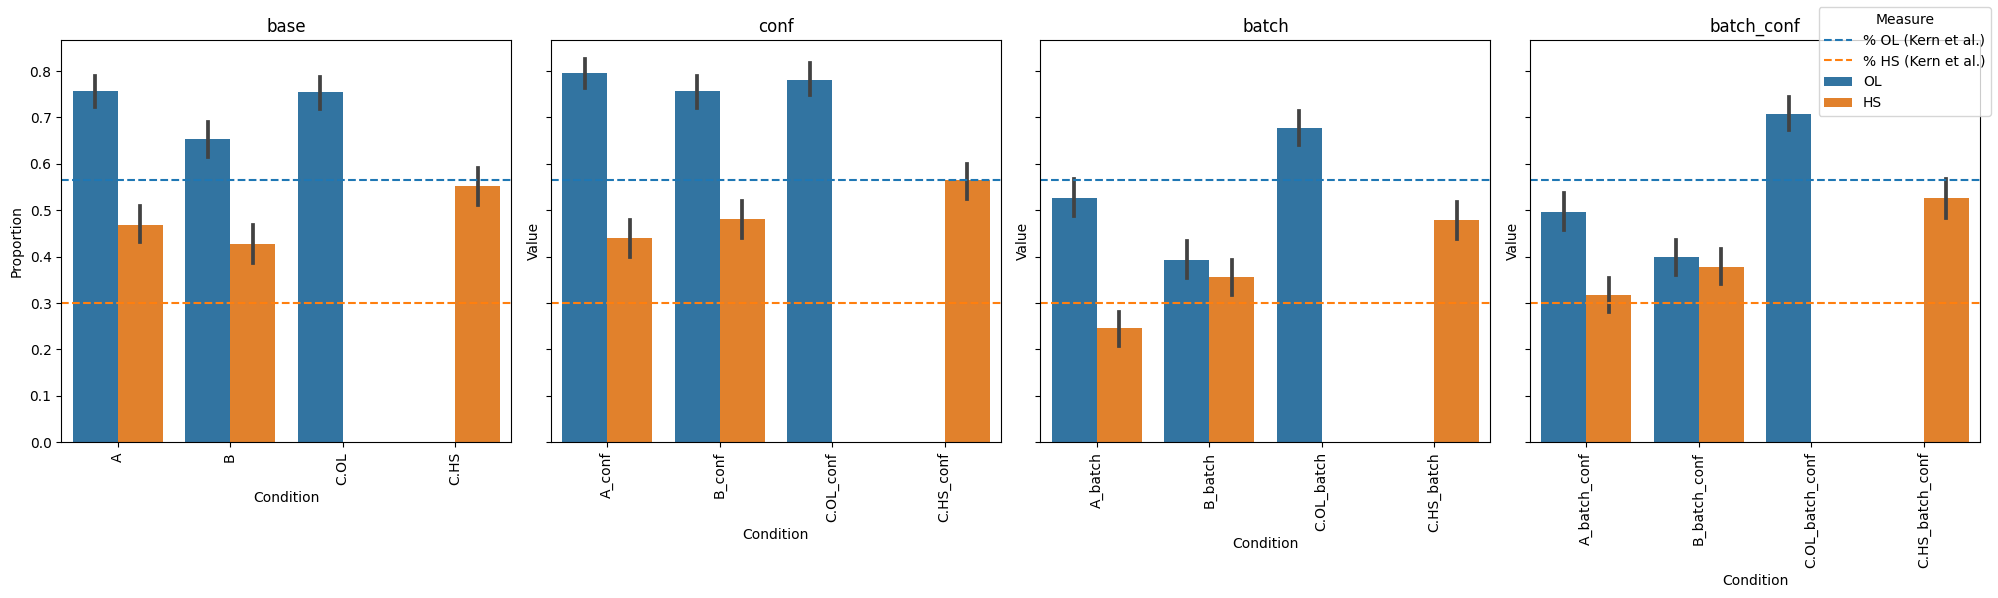

In [21]:
# Optionally, extract the base condition (everything before any underscore).
df = df_long.copy()
df['base_condition'] = df['condition'].apply(lambda x: x.split('_')[0])

# use the overall HS/OL from Kern et al. (2023) as comparison
overall_OL = final_summary.loc['overall']['OL']
overall_HS = final_summary.loc['overall']['HS']


# A custom function to extract the correct group type.
def extract_group_type(x):
    if '_' not in x:
        return 'base'
    elif x.endswith('_batch_conf'):
        return 'batch_conf'
    elif x.endswith('_conf'):
        return 'conf'
    elif x.endswith('_batch'):
        return 'batch'
    else:
        return 'other'

# Create a column for the group type.
df['group_type'] = df['condition'].apply(extract_group_type)

# Melt the DataFrame to have one row per condition-measure combination.
df_melt = df.melt(
    id_vars=['condition', 'base_condition', 'group_type'],
    value_vars=['OL', 'HS'],
    var_name='Measure',
    value_name='Value'
)

# Define the desired order for our groups.
group_order = ['base', 'conf', 'batch', 'batch_conf']

# Create subplots – one subplot per group type.
fig, axes = plt.subplots(nrows=1, ncols=len(group_order), figsize=(20, 6), sharey=True)


for ax, grp in zip(axes, group_order):
    # Subset data for the current group type.
    df_grp = df_melt[df_melt['group_type'] == grp]
    
    # Create the order for conditions for the current group.
    if grp == 'base':
        cond_order = [cond for cond in custom_order if '_' not in cond]
    elif grp == 'conf':
        # Select conditions that end with '_conf' but NOT with '_batch_conf'
        cond_order = [cond for cond in custom_order if cond.endswith('_conf') and not cond.endswith('_batch_conf')]
    elif grp == 'batch':
        # Select conditions that end with '_batch' (and not batch_conf because that is handled separately)
        cond_order = [cond for cond in custom_order if cond.endswith('_batch') and not cond.endswith('_batch_conf')]
    elif grp == 'batch_conf':
        cond_order = [cond for cond in custom_order if cond.endswith('_batch_conf')]
    
    # Plot the grouped barplot for this subgroup.
    sns.barplot(
        data=df_grp,
        x='condition',
        y='Value',
        hue='Measure',
        order=cond_order,  # enforce the correct ordering
        dodge=True,
        ax=ax, 
        palette = {'OL': '#1f77b4', # hex colors as of jacobs paper
                   'HS': '#ff7f0e'}
    )
    
    # Add a dashed horizontal line for overall OL and HS.
    # Using the same colors as defined in the palette.
    ax.axhline(y=overall_OL, linestyle="--", color="#1f77b4", label="% OL (Kern et al.)")
    ax.axhline(y=overall_HS, linestyle="--", color="#ff7f0e", label="% HS (Kern et al.)")
    
    ax.set_title(grp)
    ax.set_xlabel("Condition")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.legend().remove()

# Set a common y-axis label.
axes[0].set_ylabel("Proportion")

# Add a single common legend.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Measure", loc="upper right")

plt.tight_layout()
plt.show()

Notes to the above, it seems as:  
- labelling proportions are by far higher than in the Kern et al Paper
- asking for a confidence score in general increases the OS/HS labelling probability
- using batch prompting in general decreases the labelling probability (rather strong) 

## Rater Agreement of GPT and Kern Labelers

TODO: Check which agreement values to calculate

In [27]:
#for each tweet and each condition, calculate: 
# 1) Mode for HS and OL
# 2) Mean for HS and OL 
# 3) SD for HS/OL ratings 

from utils import mode_value

tweet_level_df = (df_long
                  .groupby(['tweet_id', 'condition', 
                             'batch_id', 'tweet_in_batch'])
                  .agg(
                        label_count = ('tweet_id', 'count'),
                        HS_mode = ('HS', mode_value),
                        HS_mean = ('HS', 'mean'),
                        HS_std = ('HS', 'std'),
                        OL_mode = ('OL', mode_value),
                        OL_mean = ('OL', 'mean'),
                        OL_std = ('OL', 'std')
).reset_index())

In [34]:
df_long.head(2)

,batch_id,tweet_in_batch,tweet_id,tweet,condition,responder,label,score,Token1,Token2,Token3,OL,HS
0,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,A_batch_conf,R1,none,4.0,NaN,NaN,NaN,0,0
1,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,B_batch_conf,R1,none,4.0,NaN,NaN,NaN,0,0


In [69]:
import numpy as np
import pandas as pd
import itertools


# Function to compute the pairwise agreement for a list of ratings.
# For a tweet with 3 ratings, there are 3 pairs.
def pair_agreement(ratings):
    # If fewer than 2 ratings, agreement cannot be computed.
    if len(ratings) < 2:
        return np.nan
    # Get all unique pairs (order doesn't matter)
    pairs = list(itertools.combinations(ratings, 2))
    # For each pair, check if the two ratings are equal: assign 1 if yes, 0 if not.
    agreements = [1 if a == b else 0 for a, b in pairs]
    return np.mean(agreements)

# Function to compute the modal rating for a series.
def mode_value(x):
    m = x.mode()
    return m.iloc[0] if not m.empty else np.nan

# --------------------------
# Step 1: Aggregate ratings per tweet per condition.
# We want, for each tweet and condition:
#  - The modal rating for HS and for OL.
#  - The within-tweet agreement for HS and for OL.
# --------------------------
df_agg = df_long.groupby(['tweet_id', 'condition']).agg(
    modal_HS = ('HS', mode_value),
    agreement_HS = ('HS', lambda x: pair_agreement(list(x))),
    modal_OL = ('OL', mode_value),
    agreement_OL = ('OL', lambda x: pair_agreement(list(x)))
).reset_index()

within_agreement = df_agg.groupby('condition').agg(
    avg_agreement_HS = ('agreement_HS', 'mean'),
    avg_agreement_OL = ('agreement_OL', 'mean')
).reset_index()

print("Within-condition (diagonal) average agreements:")
print(within_agreement)



def across_agreement(df, cond1, cond2, measure):
    # Measure should be either 'HS' or 'OL'
    col_modal = f'modal_{measure}'
    # Get modal ratings for each condition
    df1 = df[df['condition'] == cond1][['tweet_id', col_modal]].rename(columns={col_modal: f'{col_modal}_{cond1}'})
    df2 = df[df['condition'] == cond2][['tweet_id', col_modal]].rename(columns={col_modal: f'{col_modal}_{cond2}'})
    # Merge on tweet_id. Only tweets rated under both conditions are considered.
    merged = pd.merge(df1, df2, on='tweet_id')
    if merged.empty:
        return np.nan
    # Compute the fraction of tweets where the modal ratings agree.
    agree = np.mean(merged[f'{col_modal}_{cond1}'] == merged[f'{col_modal}_{cond2}'])
    return agree


# Get the list of conditions
conditions = sorted(df_long['condition'].unique())

# Prepare two empty DataFrames (one for HS and one for OL) for the across-condition agreements.
across_HS = pd.DataFrame(index=conditions, columns=conditions, dtype=float)
across_OL = pd.DataFrame(index=conditions, columns=conditions, dtype=float)

for cond_i in conditions:
    for cond_j in conditions:
        if cond_i == cond_j:
            # On the diagonal, we use the within-condition average agreement computed before.
            # We already computed that in within_agreement.
            # (For HS)
            val_hs = within_agreement.loc[within_agreement['condition'] == cond_i, 'avg_agreement_HS'].values
            across_HS.loc[cond_i, cond_j] = val_hs[0] if len(val_hs) > 0 else np.nan
            # (For OL)
            val_ol = within_agreement.loc[within_agreement['condition'] == cond_i, 'avg_agreement_OL'].values
            across_OL.loc[cond_i, cond_j] = val_ol[0] if len(val_ol) > 0 else np.nan
        else:
            # Off-diagonals: compute across-condition agreement using modal ratings.
            across_HS.loc[cond_i, cond_j] = across_agreement(df_agg, cond_i, cond_j, 'HS')
            across_OL.loc[cond_i, cond_j] = across_agreement(df_agg, cond_i, cond_j, 'OL')

print("\nKrippendorff-like (modal) agreement matrix for HS:")
across_HS

#print("\nKrippendorff-like (modal) agreement matrix for OL:")
#print(across_OL)

Within-condition (diagonal) average agreements:
          condition  avg_agreement_HS  avg_agreement_OL
0   A                0.966667          0.973333        
1   A_batch          0.930000          0.920000        
2   A_batch_conf     0.940000          0.930000        
3   A_conf           0.970000          0.986667        
4   B                0.983333          0.950000        
5   B_batch          0.956667          0.920000        
6   B_batch_conf     0.943333          0.853333        
7   B_conf           0.990000          0.950000        
8   C.HS             0.983333          1.000000        
9   C.HS_batch       0.973333          1.000000        
10  C.HS_batch_conf  0.956667          1.000000        
11  C.HS_conf        0.983333          1.000000        
12  C.OL             1.000000          0.986667        
13  C.OL_batch       1.000000          0.986667        
14  C.OL_batch_conf  1.000000          0.973333        
15  C.OL_conf        1.000000          0.986667        


,A,A_batch,A_batch_conf,A_conf,B,B_batch,B_batch_conf,B_conf,C.HS,C.HS_batch,C.HS_batch_conf,C.HS_conf,C.OL,C.OL_batch,C.OL_batch_conf,C.OL_conf
A,0.966667,0.750,0.815,0.960,0.945000,0.840000,0.865000,0.965,0.875000,0.850000,0.830000,0.885000,0.525,0.525,0.525,0.525
A_batch,0.750000,0.930,0.895,0.770,0.785000,0.850000,0.835000,0.735,0.655000,0.730000,0.680000,0.645000,0.755,0.755,0.755,0.755
A_batch_conf,0.815000,0.895,0.940,0.825,0.840000,0.855000,0.860000,0.790,0.720000,0.765000,0.735000,0.710000,0.690,0.690,0.690,0.690
A_conf,0.960000,0.770,0.825,0.970,0.955000,0.860000,0.875000,0.955,0.865000,0.870000,0.840000,0.865000,0.555,0.555,0.555,0.555
B,0.945000,0.785,0.840,0.955,0.983333,0.875000,0.890000,0.940,0.860000,0.875000,0.855000,0.860000,0.570,0.570,0.570,0.570
B_batch,0.840000,0.850,0.855,0.860,0.875000,0.956667,0.955000,0.845,0.765000,0.860000,0.810000,0.745000,0.645,0.645,0.645,0.645
B_batch_conf,0.865000,0.835,0.860,0.875,0.890000,0.955000,0.943333,0.860,0.790000,0.855000,0.835000,0.780000,0.630,0.630,0.630,0.630
B_conf,0.965000,0.735,0.790,0.955,0.940000,0.845000,0.860000,0.990,0.890000,0.865000,0.855000,0.900000,0.520,0.520,0.520,0.520
C.HS,0.875000,0.655,0.720,0.865,0.860000,0.765000,0.790000,0.890,0.983333,0.865000,0.865000,0.970000,0.440,0.440,0.440,0.440
C.HS_batch,0.850000,0.730,0.765,0.870,0.875000,0.860000,0.855000,0.865,0.865000,0.973333,0.920000,0.835000,0.515,0.515,0.515,0.515


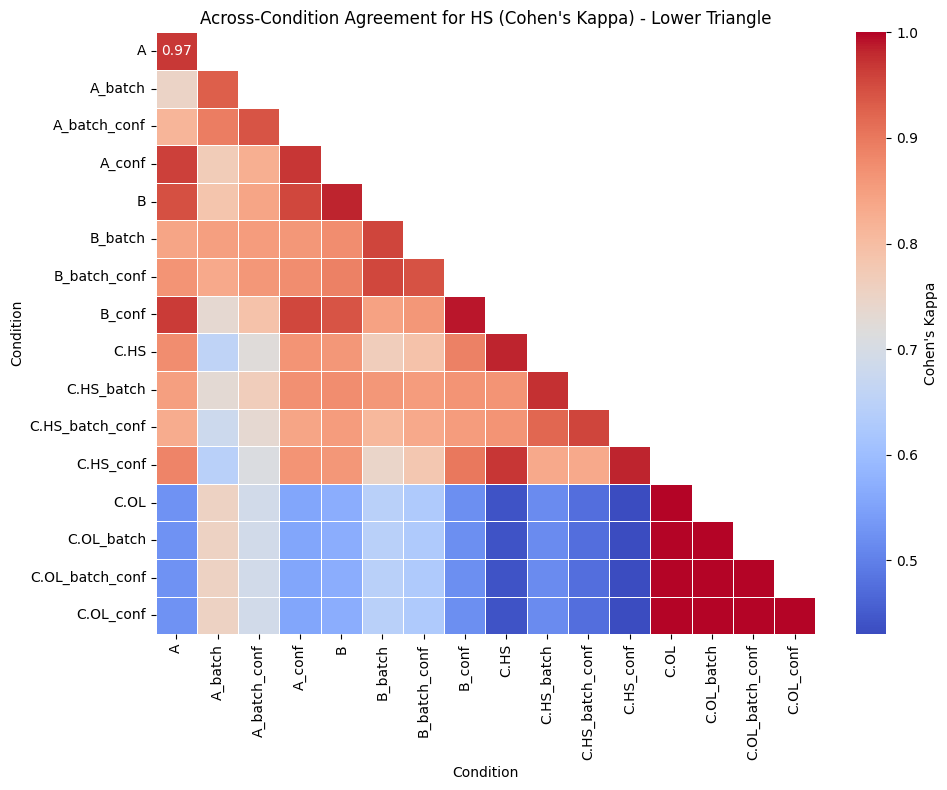

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure across_HS is in float format.
across_HS = across_HS.astype(float)

# Create a boolean mask for the upper triangle.
# np.triu returns the upper triangle of an array.
# Here, k=1 masks everything above the diagonal (the diagonal is unmasked).
mask = np.triu(np.ones_like(across_HS, dtype=bool), k=1)

# Pre-format annotation values:
# - Round the values to two decimals,
# - Convert them to strings,
# - And replace cells that are masked with an empty string.
annot = across_HS.copy().round(2).astype(str)
annot = annot.where(~mask, "")

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    across_HS,
    mask=mask,
    annot=annot,
    fmt="",   # no additional formatting is necessary since we've pre-formatted
    cmap="coolwarm",
    cbar_kws={'label': "Cohen's Kappa"},
    linewidths=0.5
)

# Move x-axis tick labels to the bottom and rotate them by 90 degrees.
ax.xaxis.tick_bottom()
plt.xticks(rotation=90)

plt.xlabel("Condition")
plt.ylabel("Condition")
plt.title("Across-Condition Agreement for HS (Cohen's Kappa) - Lower Triangle")

plt.tight_layout()
plt.show()


In [85]:
annot = annot.where(~mask, "")
annot

,A,A_batch,A_batch_conf,A_conf,B,B_batch,B_batch_conf,B_conf,C.HS,C.HS_batch,C.HS_batch_conf,C.HS_conf,C.OL,C.OL_batch,C.OL_batch_conf,C.OL_conf
A,0.97,,,,,,,,,,,,,,,
A_batch,0.75,0.93,,,,,,,,,,,,,,
A_batch_conf,0.82,0.9,0.94,,,,,,,,,,,,,
A_conf,0.96,0.77,0.82,0.97,,,,,,,,,,,,
B,0.94,0.78,0.84,0.96,0.98,,,,,,,,,,,
B_batch,0.84,0.85,0.86,0.86,0.88,0.96,,,,,,,,,,
B_batch_conf,0.86,0.84,0.86,0.88,0.89,0.96,0.94,,,,,,,,,
B_conf,0.96,0.74,0.79,0.96,0.94,0.84,0.86,0.99,,,,,,,,
C.HS,0.88,0.66,0.72,0.86,0.86,0.76,0.79,0.89,0.98,,,,,,,
C.HS_batch,0.85,0.73,0.76,0.87,0.88,0.86,0.86,0.86,0.86,0.97,,,,,,


In [35]:
# Overall agreement within (Kern) --> Kern data: tweets_full
# Overall agreement within (GPT)  --> GPT data: df_long
# Agreement between Kern and GPT labels 

import numpy as np
import pandas as pd
import krippendorff
from utils import mode_value

# ----- Helper functions -----

# 2. Given a (sub)DataFrame for one condition, pivot the ratings by tweet and annotator,
#    and compute the within-condition Krippendorff's alpha.
def compute_alpha_for_condition(df, condition, measure, annotator_col='responder'):
    # Filter to the specified condition.
    df_cond = df[df['condition'] == condition]
    # Pivot the data so that rows are tweet_id and columns are annotators.
    # The cells contain the rating for the specified measure.
    pivot = df_cond.pivot(index='tweet_id', columns=annotator_col, values=measure)
    
    # krippendorff.alpha expects a matrix where one dimension represents raters and the other units.
    # We use .to_numpy() and then transpose it.
    if pivot.empty:
        return np.nan
    # Using level_of_measurement='interval' (adjust if your ratings are ordinal, etc.)
    return krippendorff.alpha(reliability_data=pivot.to_numpy().T, level_of_measurement='interval')


# 3. For a given condition and measure, compute the modal rating per tweet.
def compute_modal_ratings(df, condition, measure):
    # Subset for the given condition.
    df_cond = df[df['condition'] == condition]
    # For each tweet, compute the modal rating (if several, take the first)
    modal = df_cond.groupby('tweet_id')[measure].apply(mode_value)
    return modal

# 4. Compute the "across" (between-condition) agreement for two conditions.
#    For each tweet, merge the modal ratings from the two conditions,
#    then compute Krippendorff's alpha on the 2-column data.
def compute_across_alpha(df, cond1, cond2, measure):
    modal_1 = compute_modal_ratings(df, cond1, measure)
    modal_2 = compute_modal_ratings(df, cond2, measure)
    # Merge modal ratings on tweet_id (only tweets rated under both conditions)
    merged = pd.merge(modal_1, modal_2, left_index=True, right_index=True, suffixes=(f"_{cond1}", f"_{cond2}"))
    if merged.empty or merged.shape[1] < 2:
        return np.nan
    # krippendorff.alpha expects data of shape (raters, items). Here our "raters" are the two conditions.
    data_matrix = merged.to_numpy().T
    return krippendorff.alpha(reliability_data=data_matrix, level_of_measurement='interval')


# ----- Main code to generate the table -----

# Choose which measure you want to evaluate. For example, we'll do it for OL.
# (You can repeat or adapt for HS as well.)
measure = 'OL'
# Get the unique conditions (for rows and columns of the final table)
conditions = sorted(df_long['condition'].unique())

# Create an empty DataFrame for storing Krippendorff's alpha values.
# Rows and columns represent conditions.
alpha_table = pd.DataFrame(index=conditions, columns=conditions, dtype=float)

# Loop over pairs of conditions.
for cond_i in conditions:
    for cond_j in conditions:
        if cond_i == cond_j:
            # Diagonal: compute within-condition agreement.
            alpha = compute_alpha_for_condition(df_long, cond_i, measure, annotator_col='responder')
            alpha_table.loc[cond_i, cond_j] = alpha
        else:
            # Off-diagonals: compute the across-condition agreement on the modal ratings.
            alpha = compute_across_alpha(df_long, cond_i, cond_j, measure)
            alpha_table.loc[cond_i, cond_j] = alpha

print("Krippendorff's alpha table (using '{}' ratings):".format(measure))
print(alpha_table)

ValueError: There has to be more than one value in the domain.

<a id="order_effects"></a>
## Order Effects in Batch Prompting Tasks?

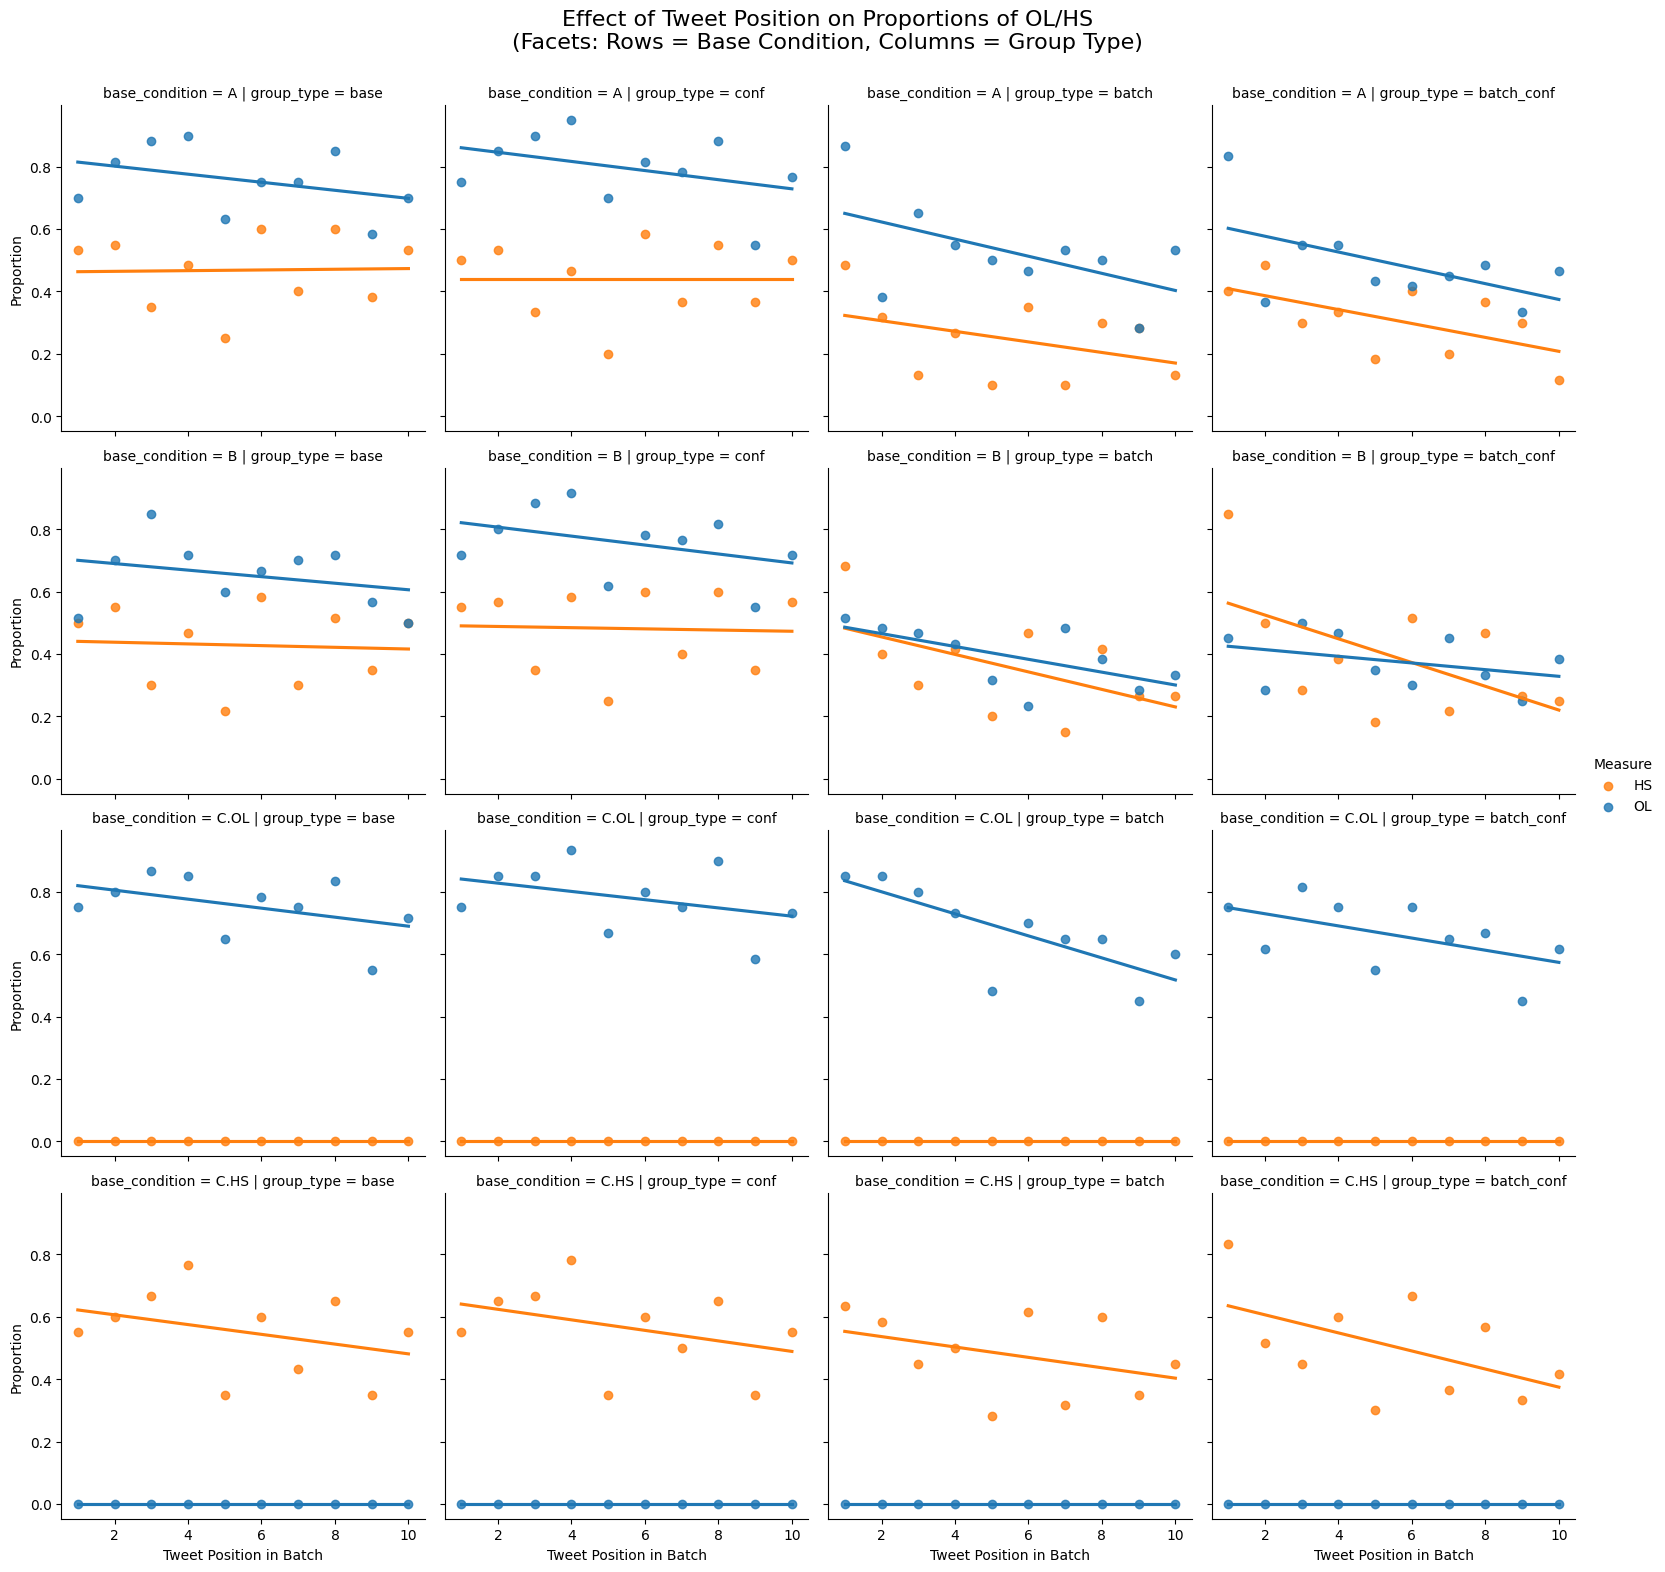

In [474]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------
# 1. Data Preparation
# ---------------------------
# It is assumed that df_long exists and has columns:
#   - 'condition'
#   - 'tweet_in_batch'
#   - 'OL' and 'HS' (binary: 1 if labeled, 0 otherwise)

# Reshape the data from wide to long: each tweet gets one row per measure
df_melt = df_long.melt(
    id_vars=['condition', 'tweet_in_batch'],
    value_vars=['OL', 'HS'],
    var_name='Measure',
    value_name='Label'
)

# Group by condition, tweet_in_batch, and measure to compute the proportion
# (since Label is binary, the mean gives the proportion)
df_prop = df_melt.groupby(
    ['condition', 'tweet_in_batch', 'Measure'], as_index=False
)['Label'].mean()
df_prop.rename(columns={'Label': 'Proportion'}, inplace=True)

# ---------------------------
# 2. Extract Condition Info
# ---------------------------
# Create column for the base condition: if there's an underscore, take the part before it; otherwise, use the whole condition
df_prop['base_condition'] = df_prop['condition'].apply(lambda x: x.split('_')[0])

# Create a custom function to extract the group type.
# We want to make sure that for conditions such as "A_batch_conf" we get 'batch_conf'
def extract_group_type(x):
    if '_' not in x:
        return 'base'
    elif x.endswith('_batch_conf'):
        return 'batch_conf'
    elif x.endswith('_conf'):
        return 'conf'
    elif x.endswith('_batch'):
        return 'batch'
    else:
        return 'other'

df_prop['group_type'] = df_prop['condition'].apply(extract_group_type)

# ---------------------------
# 3. Set the Category Orders
# ---------------------------
# For columns in the facet grid, set the order of group types and base conditions.
desired_group_order = ['base', 'conf', 'batch', 'batch_conf']
df_prop['group_type'] = pd.Categorical(df_prop['group_type'],
                                       categories=desired_group_order,
                                       ordered=True)

desired_base_order = ['A', 'B', 'C.OL', 'C.HS']
df_prop['base_condition'] = pd.Categorical(df_prop['base_condition'],
                                           categories=desired_base_order,
                                           ordered=True)

# ---------------------------
# 4. Plot with lmplot in a FacetGrid
# ---------------------------
# In each facet, tweet_in_batch is on x, and the y is the proportion.
# Each facet (given by the row and column) will have two regression lines (one per Measure).
g = sns.lmplot(
    data=df_prop,
    x='tweet_in_batch',
    y='Proportion',
    hue='Measure',              # Two lines: one for OL and one for HS
    col='group_type',           # Columns: base, conf, batch, batch_conf
    row='base_condition',       # Rows: A, B, C.OL, C.HS
    markers='o',                # Use circles for the data points
    ci=None,                    # Disable the confidence interval shading (adjust if needed)
    height=4,                   # Height of each facet
    aspect=1,                   # Aspect ratio
    order=1,                     # Linear (OLS) regression
    palette = {'OL': '#1f77b4', # hex colors as of jacobs paper
               'HS': '#ff7f0e'}
)

g.set_axis_labels("Tweet Position in Batch", "Proportion")
g.fig.subplots_adjust(top=0.92)
g.fig.suptitle("Effect of Tweet Position on Proportions of OL/HS\n(Facets: Rows = Base Condition, Columns = Group Type)", fontsize=16)

plt.show()
